# 3° Entrega Proyecto Data Science

Tema: "Energías renovables en Argentina"

### Introducción al Proyecto

El presente proyecto se enmarca en el análisis y modelado de datos aplicado al sector energético nacional, centrándose específicamente en el estudio, evolución y rendimiento de las **energías renovables y alternativas en Argentina**.

En los últimos años, la diversificación de la matriz energética y la transición hacia fuentes limpias se han convertido en pilares fundamentales para el desarrollo sostenible. En este contexto, la aplicación de técnicas de **Ciencia de Datos** permite transformar registros históricos y operativos en información de alto valor estratégico, facilitando la comprensión del comportamiento real de la infraestructura instalada frente a su producción energética efectiva.

### Objetivos Principales
* **Análisis Exploratorio de Datos (EDA):** Examinar la estructura, distribución y calidad de los datos relativos a la potencia instalada y la generación mensual.
* **Pregunta de Negocio:** Analizar la relación directa entre la capacidad técnica disponible (potencia instalada medida en **MW**) y la energía real producida (medida en **MWh**).
* **Modelado No Supervisado (Clustering):** Implementar el algoritmo **K-Means** para segmentar de manera objetiva las diferentes tecnologías según sus escalas de desarrollo y rendimiento, validando los hallazgos mediante el Método del Codo (Inercia) y la Puntuación de la Silueta.

A través de este recorrido analítico, el proyecto busca ofrecer una perspectiva cuantitativa y fundamentada sobre el estado actual, las brechas y el potencial de las distintas fuentes de energía limpia en el sistema.

**Análisis Exploratorio de Datos**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df = pd.read_csv('/content/energias-alternativas.csv', encoding='latin-1')

In [ ]:
df

,sector_id,sector_nombre,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,fuente,frecuencia_nombre,cobertura_nombre,alcance_tipo,alcance_id,alcance_nombre,indice_tiempo,valor
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5306,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-08-01,61.200
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.200
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.200
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.200


In [ ]:
print(f"Dimensiones originales: {df.shape[0]} filas y {df.shape[1]} columnas\n")

Dimensiones originales: 5311 filas y 14 columnas



In [ ]:
df = df.rename(columns= {
        'sector_id': 'id_sector',
        'sector_nombre': 'sector',
        'variable_id': 'id_variable',
        'actividad_producto_nombre': 'tecnologia',
        'indicador': 'indicador',
        'unidad_de_medida': 'unidad',
        'fuente': 'fuente_datos',
        'frecuencia_nombre': 'frecuencia',
        'cobertura_nombre': 'cobertura',
        'alcance_tipo': 'tipo_region',
        'alcance_id': 'id_provincia',
        'alcance_nombre': 'provincia',
        'indice_tiempo': 'fecha',
        'valor': 'medicion'
})

In [ ]:
df

,id_sector,sector,id_variable,tecnologia,indicador,unidad,fuente_datos,frecuencia,cobertura,tipo_region,id_provincia,provincia,fecha,medicion
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5306,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-08-01,61.200
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.200
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.200
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.200


In [ ]:
df.head(n=4)


,id_sector,sector,id_variable,tecnologia,indicador,unidad,fuente_datos,frecuencia,cobertura,tipo_region,id_provincia,provincia,fecha,medicion
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.0
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.0
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.0
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.0


In [ ]:
df.tail(n=4)

,id_sector,sector,id_variable,tecnologia,indicador,unidad,fuente_datos,frecuencia,cobertura,tipo_region,id_provincia,provincia,fecha,medicion
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.2
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.2
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.2
5310,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-12-01,61.2


In [ ]:
df.isna().sum()

,0
id_sector,0
sector,0
id_variable,0
tecnologia,0
indicador,0
unidad,0
fuente_datos,0
frecuencia,0
cobertura,0
tipo_region,0


In [ ]:
(df == 0). sum()
# Cantidad de ceros por columna

,0
id_sector,0
sector,0
id_variable,0
tecnologia,0
indicador,0
unidad,0
fuente_datos,0
frecuencia,0
cobertura,0
tipo_region,0


In [ ]:
display(df.describe())
display(df.describe(include="object"))

,id_sector,id_variable,id_provincia,medicion
count,5311.0,5311.000000,5311.000000,5311.000000
mean,25.0,445.452834,46.702693,20086.474353
std,0.0,2.844691,29.186850,75980.809927
min,25.0,440.000000,6.000000,0.000000
25%,25.0,443.000000,14.000000,19.500000
50%,25.0,447.000000,50.000000,349.850000
75%,25.0,448.000000,70.000000,9156.317500
max,25.0,450.000000,90.000000,752501.256000


,sector,tecnologia,indicador,unidad,fuente_datos,frecuencia,cobertura,tipo_region,provincia,fecha
count,5311,5311,5311,5311,5311,5311,5311,5311,5311,5311
unique,1,6,2,2,1,1,1,1,19,120
top,Energías alternativas,Energía pah,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,BUENOS AIRES,2020-12-01
freq,5311,2172,3072,3072,5311,5311,5311,5311,792,72


## Pregunta de Negocio

Variable objetivo: 'Generación de Energía'

**¿Se puede predecir la generación (MWh) de enegía a de fuentes  renovables a partir de la potencia instalada?**

Se plantea separar el dataset original en dos datasets, uno por generación y otro por potencia instalada. De esta manera la variable indicador del dataset original queda deslgosada por generación y potencia, las demás columnas quedan sin efecto.

In [ ]:
# Dataset 1: Exclusivo de Generación (MWh)
df_gen = df[df['indicador'] == 'Generación'].copy()
df_gen = df_gen.drop(columns=['indicador'])

In [ ]:
#Dataset 2: Exclusivo de Potencia Instalada (MW)
df_pot = df[df['indicador'] == 'Potencia instalada'].copy()
df_pot = df_pot.drop(columns=['indicador'])

In [ ]:
print(df_gen['tecnologia'].value_counts())
print(df_pot['tecnologia'].value_counts())

tecnologia
Energía pah        1200
Energía biomasa     540
Energía eólica      528
Energía solar       288
Energía biogás      276
Energía nuclear     240
Name: count, dtype: int64
tecnologia
Energía pah        972
Energía eólica     499
Energía biogás     276
Energía solar      276
Energía nuclear    216
Name: count, dtype: int64


In [ ]:
display(df_gen.head())


,id_sector,sector,id_variable,tecnologia,unidad,fuente_datos,frecuencia,cobertura,tipo_region,id_provincia,provincia,fecha,medicion
0,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000
1,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000
2,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000
3,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000
4,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924


In [ ]:
display(df_pot.head())

,id_sector,sector,id_variable,tecnologia,unidad,fuente_datos,frecuencia,cobertura,tipo_region,id_provincia,provincia,fecha,medicion
276,25,Energías alternativas,441,Energía biogás,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.0
277,25,Energías alternativas,441,Energía biogás,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.0
278,25,Energías alternativas,441,Energía biogás,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.0
279,25,Energías alternativas,441,Energía biogás,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.0
280,25,Energías alternativas,441,Energía biogás,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,5.1


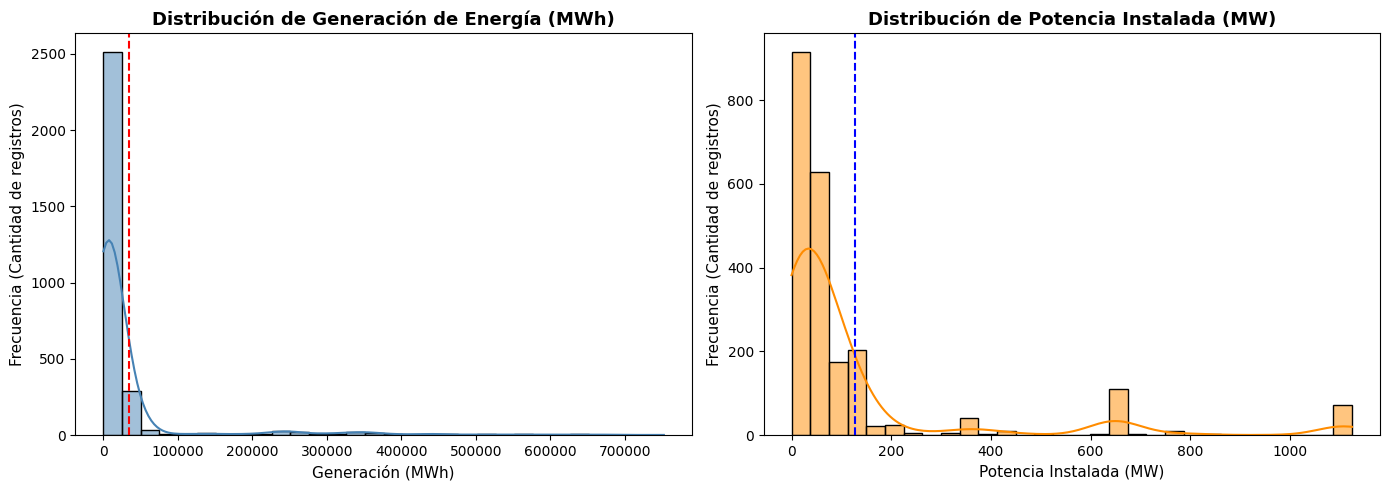

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histograma 1: Generación de Energía (MWh)

sns.histplot(df_gen['medicion'], bins=30, kde=True, color='steelblue', ax=axes[0])
axes[0].axvline(df_gen['medicion'].mean(), color="red", ls="--", label="media")
axes[0].set_title('Distribución de Generación de Energía (MWh)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Generación (MWh)', fontsize=11)
axes[0].set_ylabel('Frecuencia (Cantidad de registros)', fontsize=11)


# 2. Histograma para el Dataset de Potencia Instalada (MW)

sns.histplot(df_pot['medicion'], bins=30, kde=True, color='darkorange', ax=axes[1])
axes[1].axvline(df_pot['medicion'].mean(), color="blue", ls="--", label="media")
axes[1].set_title('Distribución de Potencia Instalada (MW)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Potencia Instalada (MW)', fontsize=11)
axes[1].set_ylabel('Frecuencia (Cantidad de registros)', fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
df_gen['medicion'].mean()

np.float64(34633.5768343099)

In [ ]:
df_pot['medicion'].mean()

np.float64(127.25201205895489)

Histograma de Generación (MWh): Refleja la energía real producida mes a mes. Se mantiene una fuerte concentración en valores bajos y ceros (meses inactivos), con una larga cola hacia la derecha debido a grandes fuentes de generación.

Histograma de Potencia Instalada (MW): Refleja la capacidad instalada de infraestructura. Al estar en otra escala y unidad, nos permite analizar la distribución de la potencia nominal de manera independiente, revelando clústeres específicos de capacidad en el sistema eléctrico argentino sin distorsión por parte de los volúmenes mensuales de generación.

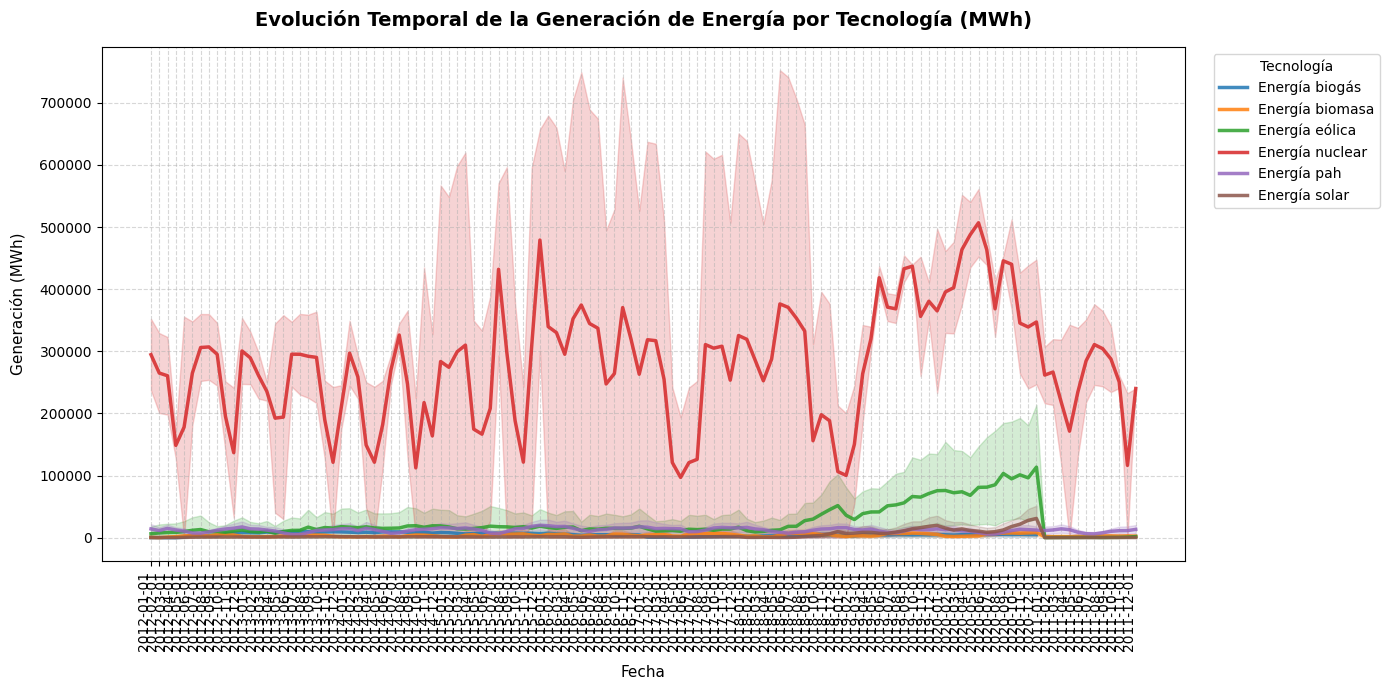

In [ ]:
# 1. GRÁFICO DE LÍNEAS MEJORADO: EVOLUCIÓN TEMPORAL POR TECNOLOGÍA
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_gen,
    x='fecha',
    y='medicion',
    hue='tecnologia',
    palette='tab10',
    linewidth=2.5,
    alpha=0.85
)

plt.title('Evolución Temporal de la Generación de Energía por Tecnología (MWh)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Fecha', fontsize=11, labelpad=10)
plt.ylabel('Generación (MWh)', fontsize=11, labelpad=10)

# Leyenda y Rejilla
plt.legend(title='Tecnología', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# ANÁLISIS DE OUTLIERS (IQR) EN GENERACIÓN
Q1 = df_gen['medicion'].quantile(0.25)
Q3 = df_gen['medicion'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

outliers = df_gen[df_gen['medicion'] > limite_superior]

print("="*60)
print("AUDITORÍA TÉCNICA DE OUTLIERS EN GENERACIÓN")
print("="*60)
print(f"Total de registros analizados: {len(df_gen)}")
print(f"Registros por encima del límite superior estadístico: {len(outliers)} ({len(outliers)/len(df_gen)*100:.2f}%)")
print("\nDesglose de tecnologías presentes en estos valores altos:")
print(outliers['tecnologia'].value_counts())
print("\nConclusión: No son errores, reflejan la alta capacidad real de generación nuclear y eólica.")
print("="*60)

AUDITORÍA TÉCNICA DE OUTLIERS EN GENERACIÓN
Total de registros analizados: 3072
Registros por encima del límite superior estadístico: 356 (11.59%)

Desglose de tecnologías presentes en estos valores altos:
tecnologia
Energía nuclear    182
Energía eólica     136
Energía pah         25
Energía solar       13
Name: count, dtype: int64

Conclusión: No son errores, reflejan la alta capacidad real de generación nuclear y eólica.


In [ ]:
df_cruzado = pd.merge(df_gen, df_pot, on=['fecha', 'tecnologia', 'provincia'], how='inner')

In [ ]:
df_cruzado

,id_sector_x,sector_x,id_variable_x,tecnologia,unidad_x,fuente_datos_x,frecuencia_x,cobertura_x,tipo_region_x,id_provincia_x,...,id_sector_y,sector_y,id_variable_y,unidad_y,fuente_datos_y,frecuencia_y,cobertura_y,tipo_region_y,id_provincia_y,medicion_y
0,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,...,25,Energías alternativas,441,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,0.0
1,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,...,25,Energías alternativas,441,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,0.0
2,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,...,25,Energías alternativas,441,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,0.0
3,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,...,25,Energías alternativas,441,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,0.0
4,25,Energías alternativas,440,Energía biogás,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,...,25,Energías alternativas,441,MW,CAMMESA,Mensual,Nacional,PROVINCIA,6,5.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2222,25,Energías alternativas,449,Energía solar,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,74,...,25,Energías alternativas,450,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,61.2
2223,25,Energías alternativas,449,Energía solar,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,74,...,25,Energías alternativas,450,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,61.2
2224,25,Energías alternativas,449,Energía solar,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,74,...,25,Energías alternativas,450,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,61.2
2225,25,Energías alternativas,449,Energía solar,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,74,...,25,Energías alternativas,450,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,61.2


In [ ]:
df_cruzado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2227 entries, 0 to 2226
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_sector_x     2227 non-null   int64  
 1   sector_x        2227 non-null   object 
 2   id_variable_x   2227 non-null   int64  
 3   tecnologia      2227 non-null   object 
 4   unidad_x        2227 non-null   object 
 5   fuente_datos_x  2227 non-null   object 
 6   frecuencia_x    2227 non-null   object 
 7   cobertura_x     2227 non-null   object 
 8   tipo_region_x   2227 non-null   object 
 9   id_provincia_x  2227 non-null   int64  
 10  provincia       2227 non-null   object 
 11  fecha           2227 non-null   object 
 12  medicion_x      2227 non-null   float64
 13  id_sector_y     2227 non-null   int64  
 14  sector_y        2227 non-null   object 
 15  id_variable_y   2227 non-null   int64  
 16  unidad_y        2227 non-null   object 
 17  fuente_datos_y  2227 non-null   o

In [ ]:
df_cruzado = pd.merge(
    df_gen[['fecha', 'tecnologia', 'provincia', 'medicion']],
    df_pot[['fecha', 'tecnologia', 'provincia', 'medicion']],
    on=['fecha', 'tecnologia', 'provincia'],
    how='inner',
    suffixes=('_gen', '_pot')
).rename(columns={'medicion_gen': 'medicion_x',
                  'medicion_pot': 'medicion_y'}
)

In [ ]:
df_cruzado

,fecha,tecnologia,provincia,medicion_x,medicion_y
0,2012-01-01,Energía biogás,BUENOS AIRES,0.000,0.0
1,2012-02-01,Energía biogás,BUENOS AIRES,0.000,0.0
2,2012-03-01,Energía biogás,BUENOS AIRES,0.000,0.0
3,2012-04-01,Energía biogás,BUENOS AIRES,0.000,0.0
4,2012-05-01,Energía biogás,BUENOS AIRES,764.924,5.1
...,...,...,...,...,...
2222,2020-08-01,Energía solar,SAN LUIS,11169.577,61.2
2223,2020-09-01,Energía solar,SAN LUIS,13717.535,61.2
2224,2020-10-01,Energía solar,SAN LUIS,14944.585,61.2
2225,2020-11-01,Energía solar,SAN LUIS,15798.333,61.2


In [ ]:
df_cruzado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2227 entries, 0 to 2226
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       2227 non-null   object 
 1   tecnologia  2227 non-null   object 
 2   provincia   2227 non-null   object 
 3   medicion_x  2227 non-null   float64
 4   medicion_y  2227 non-null   float64
dtypes: float64(2), object(3)
memory usage: 87.1+ KB


In [ ]:
# Correción de nombres genéricos (medicion_x, medicion_y) a nombres semánticos
df_cruzado = df_cruzado.rename(columns={
    'medicion_x': 'generacion_mwh',
    'medicion_y': 'potencia_mw'
})

print("Nombres de columnas actualizados:")
display(df_cruzado.head())


Nombres de columnas actualizados:


,fecha,tecnologia,provincia,generacion_mwh,potencia_mw
0,2012-01-01,Energía biogás,BUENOS AIRES,0.000,0.0
1,2012-02-01,Energía biogás,BUENOS AIRES,0.000,0.0
2,2012-03-01,Energía biogás,BUENOS AIRES,0.000,0.0
3,2012-04-01,Energía biogás,BUENOS AIRES,0.000,0.0
4,2012-05-01,Energía biogás,BUENOS AIRES,764.924,5.1


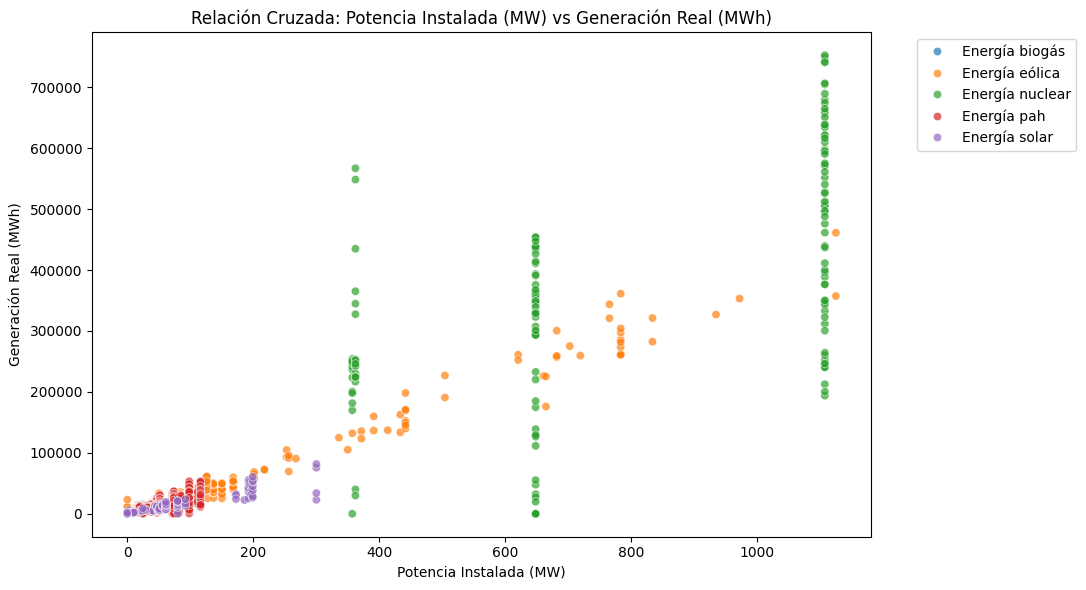

In [ ]:
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_cruzado,
    x='potencia_mw', # Potencia Instalada
    y='generacion_mwh', # Generación Real
    hue='tecnologia',
    palette='tab10',
    alpha=0.7
)
plt.title('Relación Cruzada: Potencia Instalada (MW) vs Generación Real (MWh)')
plt.xlabel('Potencia Instalada (MW)')
plt.ylabel('Generación Real (MWh)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('scatter_cruzado.png')
plt.show()


###Interpretación clave de este gráfico:
*Comportamientos Operativos Diferenciados:*

La Energía Nuclear (en verde) se agrupa verticalmente en niveles fijos de potencia instalada (alrededor de los 350 MW, 650 MW y 1100 MW), pero con una dispersión enorme en la generación real. Esto ocurre porque la potencia nominal se mantiene constante, pero la generación mensual varía debido a paradas técnicas, mantenimientos programados o recarga de combustible de los reactores.

La Energía Eólica (en naranja) muestra una tendencia ascendente más proporcional a medida que incrementa su capacidad instalada en los parques a lo largo de los años.

Las tecnologías de menor escala (como biogás, biomasa, solar y pah) se concentran en la esquina inferior izquierda con valores compactos de baja potencia y baja generación.

### Observación

Si removemos la Energía Nuclear (que es un caso atípico absoluto con una operación de factor de carga masivo y constante que rompía la proporción lineal), el comportamiento entre la Potencia Instalada (MW) y la Generación Real (MWh) para el resto de las tecnologías (eólica, solar, biomasa, biogás y pequeños aprovechamientos hidroeléctricos) se vuelve altamente lineal. Además la energía nuclear no es alternativa.

## Regresión Lineral: predecir la Generación de Enrgía en MWh

**Target:** generación de energía  
**Features:** potencia

Métricas de esta parte (solo dos):

* **MAE** — error absoluto medio.
* **R²** — 1 es perfecto, 0 es “igual que predecir la media”.



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

In [ ]:
# --- MODELO 1: REGRESIÓN LINEAL
# 'potencia_mw' representa la Potencia Instalada (X)
# 'generacion_mwh' representa la Generación Real (y)
X_lr = df_cruzado[['potencia_mw']]
y = df_cruzado['generacion_mwh']

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(X_lr, y, test_size=0.2, random_state=42)

# Dummy Baseline (usando el mismo split)
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_lr, y_train_lr)
y_pred_dummy = dummy.predict(X_test_lr)

# Regresión Lineal
lr = LinearRegression()
lr.fit(X_train_lr, y_train_lr)
y_pred_lr = lr.predict(X_test_lr)

**Métricas**

In [ ]:
# Evaluación del Baseline Dummy
mae_dummy = mean_absolute_error(y_test_lr, y_pred_dummy)
r2_dummy = r2_score(y_test_lr, y_pred_dummy)

# Evaluación de la Regresión Lineal
mae_lr = mean_absolute_error(y_test_lr, y_pred_lr)
r2_lr = r2_score(y_test_lr, y_pred_lr)

print("="*50)
print("MÉTRICAS DEL MODELO DUMMY (BASELINE)")
print("="*50)
print(f"MAE: {mae_dummy:,.2f} MWh")
print(f"R²:  {r2_dummy:.4f}")

print("\n" + "="*50)
print("MÉTRICAS DE LA REGRESIÓN LINEAL")
print("="*50)
print(f"MAE: {mae_lr:,.2f} MWh")
print(f"R²:  {r2_lr:.4f}")
print("="*50)

MÉTRICAS DEL MODELO DUMMY (BASELINE)
MAE: 57,385.02 MWh
R²:  -0.0000

MÉTRICAS DE LA REGRESIÓN LINEAL
MAE: 23,700.46 MWh
R²:  0.7106


**Con el objetivo de aumentar el R2, se elimina el tipo de tecnología de energía nuclear, y se vuelve a realizar la regresión lineal**


In [ ]:
# EXCLUIR ENERGÍA NUCLEAR
df_depurado = df_cruzado[df_cruzado['tecnologia'] != 'Energía nuclear'].copy()

In [ ]:
df_depurado

,fecha,tecnologia,provincia,generacion_mwh,potencia_mw
0,2012-01-01,Energía biogás,BUENOS AIRES,0.000,0.0
1,2012-02-01,Energía biogás,BUENOS AIRES,0.000,0.0
2,2012-03-01,Energía biogás,BUENOS AIRES,0.000,0.0
3,2012-04-01,Energía biogás,BUENOS AIRES,0.000,0.0
4,2012-05-01,Energía biogás,BUENOS AIRES,764.924,5.1
...,...,...,...,...,...
2222,2020-08-01,Energía solar,SAN LUIS,11169.577,61.2
2223,2020-09-01,Energía solar,SAN LUIS,13717.535,61.2
2224,2020-10-01,Energía solar,SAN LUIS,14944.585,61.2
2225,2020-11-01,Energía solar,SAN LUIS,15798.333,61.2


In [ ]:
# Se vuelven a renombrar las columnas esta vez para el df_depurado
df_depurado = df_depurado.rename(columns={
    'medicion_x': 'generacion_mwh',
    'medicion_y': 'potencia_mw'
})

# Extraemos las variables con los nombres correctos
X_lr = df_depurado[['potencia_mw']]
y = df_depurado['generacion_mwh']

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(X_lr, y, test_size=0.2, random_state=42)

print(f"Train: {X_train_lr.shape[0]} filas")
print(f"Test: {X_test_lr.shape[0]} filas")

Train: 1608 filas
Test: 403 filas


In [ ]:
# Dummy Baseline
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_lr, y_train_lr)
y_pred_dummy = dummy.predict(X_test_lr)
mae_dummy = mean_absolute_error(y_test_lr, y_pred_dummy)
r2_dummy = r2_score(y_test_lr, y_pred_dummy)

# Regresión Lineal
lr = LinearRegression()
lr.fit(X_train_lr, y_train_lr)
y_pred_lr = lr.predict(X_test_lr)
mae_lr = mean_absolute_error(y_test_lr, y_pred_lr)
r2_lr = r2_score(y_test_lr, y_pred_lr)

print("="*50)
print(f"METRICAS MODELO DUMMY -> MAE: {mae_dummy:.2f} MWh, R2: {r2_dummy:.4f}")
print("="*50)
print(f"METRICAS REGRESIÓN LINEAL -> MAE: {mae_lr:.2f} Mwh, R2: {r2_lr:.4f}")
print("="*50)

METRICAS MODELO DUMMY -> MAE: 17744.07 MWh, R2: -0.0011
METRICAS REGRESIÓN LINEAL -> MAE: 6637.87 Mwh, R2: 0.9489


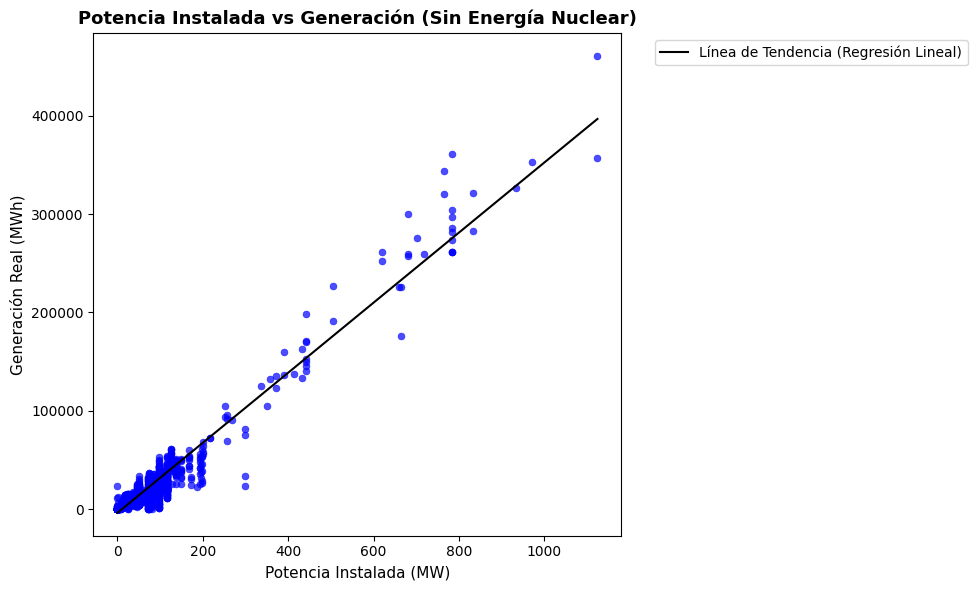

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_depurado,
    x='potencia_mw',
    y='generacion_mwh',
    color='blue',
    alpha=0.7,           # Transparencia para notar la concentracion de puntos
    s=25,                # Tamaño de los puntos
    edgecolor=None

)

# Línea de tendencia de la Regresión Lineal
X_linea = df_depurado[['potencia_mw']].sort_values(by='potencia_mw')
y_linea_pred = lr.predict(X_linea)

plt.plot(
    X_linea['potencia_mw'],
    y_linea_pred,
    color='black',
    linewidth=1.5,
    label='Línea de Tendencia (Regresión Lineal)'
)

# Etiquetas, títulos y leyenda
plt.title('Potencia Instalada vs Generación (Sin Energía Nuclear)', fontsize=13, fontweight='bold')
plt.xlabel('Potencia Instalada (MW)', fontsize=11)
plt.ylabel('Generación Real (MWh)', fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('Reg_Lineal', dpi=300)
plt.show()





In [ ]:
# Evaluar en entrenamiento
y_pred_train = lr.predict(X_train_lr)
r2_train = r2_score(y_train_lr, y_pred_train)

# Evaluar en prueba (test)
y_pred_test = lr.predict(X_test_lr)
r2_test = r2_score(y_test_lr, y_pred_test)

print(f"R² en Train: {r2_train:.4f}")
print(f"R² en Test:  {r2_test:.4f}")

R² en Train: 0.9313
R² en Test:  0.9489


In [ ]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

# Usamos el modelo 'lr' que fue entrenado previamente
modelo_lr = lr

# Configuramos la validación cruzada por pliegues (5 pliegues)
# shuffle=True mezcla los datos antes de dividirlos para evitar sesgos por orden temporal
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Evaluamos el modelo usando el coeficiente de determinación (R^2)
scores_r2 = cross_val_score(modelo_lr, X_lr, y, cv=kf, scoring='r2') # "X_lr" e "y" son del dataset df_depurado

# 4. También podemos evaluar el Error Cuadrático Medio Negativo (RMSE)
scores_rmse = cross_val_score(modelo_lr, X_lr, y, cv=kf, scoring='neg_root_mean_squared_error')

rmse_positivo = -scores_rmse  # Convertimos a positivo para interpretarlo mejor

# 5. Imprimimos los resultados detallados y el promedio final
print('='*60)
print('RESULTADOS DE VALIDACIÓN CRUZADA CON 5 PLIEGUES')
print('='*60)
print(f'R^2 por pliegue: {np.round(scores_r2, 4)}')
print(f'R^2 Promedio: {scores_r2.mean():.4f} (Desviación estándar: +/- {scores_r2.std():.4f})\n')
print('-'*60)
print(f'RMSE por pliegue: {np.round(rmse_positivo, 2)}')
print(f'RMSE Promedio: {rmse_positivo.mean():.2f} (+/- {rmse_positivo.std():.2f})')
print('='*60)

RESULTADOS DE VALIDACIÓN CRUZADA CON 5 PLIEGUES
R^2 por pliegue: [0.9489 0.9628 0.8981 0.9252 0.9173]
R^2 Promedio: 0.9305 (Desviación estándar: +/- 0.0230)

------------------------------------------------------------
RMSE por pliegue: [ 9767.33  8182.92 10183.85  9612.43 10047.98]
RMSE Promedio: 9558.90 (+/- 716.85)


In [ ]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# 1. Se asegura el ordenamiento cronológico del data set
df_depurado['fecha'] = pd.to_datetime(df_depurado['fecha'])
df_depurado = df_depurado.sort_values(by='fecha').reset_index(drop=True)

X_ts = df_depurado[['potencia_mw']]
y_ts = df_depurado['generacion_mwh']

# 2. Configuarcion de TimeSeriesSplit (5 pliegues cornológicos)
# Respeta la flecha del tiempo: entrena con el pasado y evalúa en el futuro inmediato
tscv = TimeSeriesSplit(n_splits=5)

# 3. Evaluacion de R2 y RMSE respetando la secuencia temporal
scores_r2 = cross_val_score (lr, X_ts, y_ts, cv=tscv, scoring='r2')
scores_rmse = -cross_val_score (lr,X_ts, y_ts, cv=tscv, scoring= 'neg_root_mean_squared_error' )

print('='*60)
print('VALIDACIÓN CRUZADA CON TIMESERIESSPLIT (ACORDE A SERIES TEMPORALES)')
print('='*60)
print(f'R² por pliegue temporal:   {np.round(scores_r2, 4)}')
print(f'R² Promedio:               {scores_r2.mean():.4f} (+/- {scores_r2.std():.4f})')
print('-'*60)
print(f'RMSE por pliegue temporal: {np.round(scores_rmse, 2)}')
print(f'RMSE Promedio:             {scores_rmse.mean():.2f} MWh (+/- {scores_rmse.std():.2f})')
print('='*60)


VALIDACIÓN CRUZADA CON TIMESERIESSPLIT (ACORDE A SERIES TEMPORALES)
R² por pliegue temporal:   [0.6866 0.7283 0.8569 0.8904 0.9562]
R² Promedio:               0.8237 (+/- 0.1010)
------------------------------------------------------------
RMSE por pliegue temporal: [ 7096.7   6912.09  7587.53 14938.96 15201.39]
RMSE Promedio:             10347.34 MWh (+/- 3863.39)


In [ ]:
df_depurado

,fecha,tecnologia,provincia,generacion_mwh,potencia_mw
0,2012-01-01,Energía biogás,BUENOS AIRES,0.000,0.00
1,2012-01-01,Energía eólica,LA RIOJA,844.759,2.10
2,2012-01-01,Energía pah,CORDOBA,19331.791,111.60
3,2012-01-01,Energía eólica,BUENOS AIRES,18.659,0.25
4,2012-01-01,Energía pah,CHUBUT,11705.380,46.80
...,...,...,...,...,...
2006,2020-12-01,Energía pah,CORDOBA,14948.581,116.00
2007,2020-12-01,Energía pah,SANTIAGO DEL ESTERO,5244.672,19.50
2008,2020-12-01,Energía biogás,TUCUMAN,6.703,3.00
2009,2020-12-01,Energía solar,SALTA,21071.160,80.00


### Modelado No Supervisado: Clustering de Tecnologías Energéticas

En esta sección, aplicamos técnicas de aprendizaje no supervisado con el objetivo de identificar patrones y agrupamientos naturales (`clusters`) dentro del sistema energético, sin depender de una variable objetivo previa. A través de este enfoque, buscamos segmentar las observaciones en función de su potencia instalada y su capacidad de generación, permitiendo caracterizar de forma objetiva la estructura y el comportamiento real de las fuentes renovables en el país.

In [ ]:
from sklearn.preprocessing import StandardScaler

X_cluster=df_depurado[['potencia_mw', 'generacion_mwh']]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X_cluster)
#normalizamos los datos a escala similar para evitar que una var domine

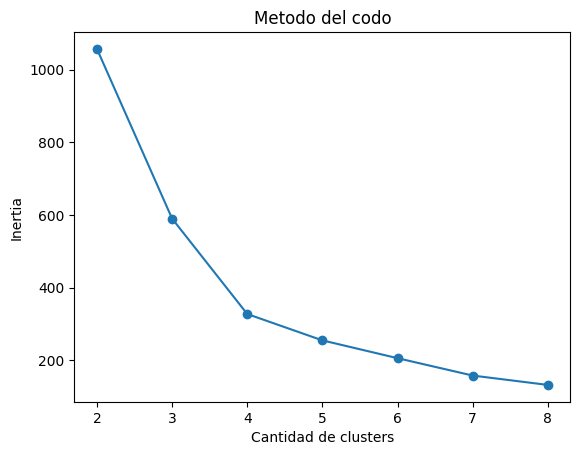

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inercias=[]
for k in range(2, 9):
    modelo=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
    )
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)
plt.plot(range(2, 9), inercias, marker='o')
plt.xlabel('Cantidad de clusters')
plt.ylabel('Inertia')
plt.title("Metodo del codo")
plt.show()


Validamos con la puntuacion de la silueta

In [ ]:
from sklearn.metrics import silhouette_score
for k in range(2, 9):
    modelo=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
    )
    labels=modelo.fit_predict(X_scaled)
    score=silhouette_score(X_scaled, labels)
    print(f"K={k} -> Silhoutte= {score:.3f}")

K=2 -> Silhoutte= 0.912
K=3 -> Silhoutte= 0.652
K=4 -> Silhoutte= 0.648
K=5 -> Silhoutte= 0.522
K=6 -> Silhoutte= 0.520
K=7 -> Silhoutte= 0.519
K=8 -> Silhoutte= 0.519


Podemos ver que el mejor resultado aparece en K=3

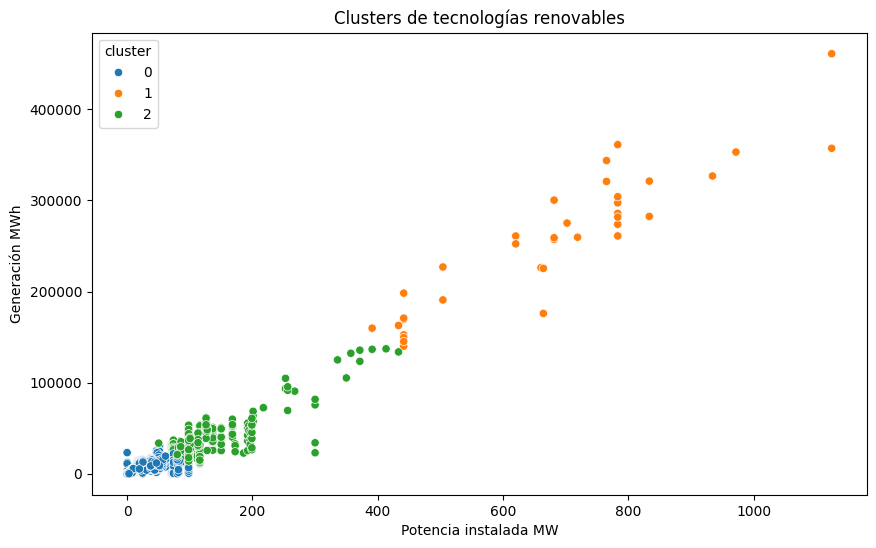

In [ ]:
kmeans=KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
)
df_depurado['cluster']=kmeans.fit_predict(X_scaled)
#Ahora que tenemos el modelo lo volcamos al grafico
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_depurado,
    x='potencia_mw',
    y='generacion_mwh',
    hue='cluster',
    palette='tab10'
)
plt.title("Clusters de tecnologías renovables")
plt.xlabel("Potencia instalada MW")
plt.ylabel("Generación MWh")
plt.show()


**A partir de la segmentación mediante K-Means ($K=3$), se identifican tres perfiles claros en el comportamiento tecnológico del sistema:**

Clúster 0 (Azul - Baja Escala): Agrupa registros con baja potencia instalada y poca generación, correspondientes a tecnologías de menor escala o etapas de desarrollo inicial.

Clúster 2 (Verde - Desarrollo Intermedio): Representa a tecnologías con capacidad y producción moderada, que operan como un segmento de transición o expansión sostenida dentro del sistema.

Clúster 1 (Naranja - Alta Escala / Liderazgo): Concentra a las tecnologías más robustas y relevantes del país, donde la potencia instalada supera los 400–1000 MW y se alcanzan los mayores volúmenes de producción energética."*